# **VALIDASI METODE 4 PAPER YANG LOLOS REPLIKASI KE DATASET YOUTUBE PORTUGAL VS KROASIA**
### **Cross-Dataset Benchmark & Evaluasi Lengkap Standar Pertemuan 5 & 6**
*Kelompok 1: Josua Eriek Kurniawan (15241108), Syahid Ahmad Yasin (15241007), Raditya Fernanda Putra (15241034)*

---
Notebook ini menguji **murni 4 paper yang berhasil LOLOS replikasi di Colab** (`Replikasi_Lolos/`) pada dataset komentar YouTube berbahasa Indonesia laga Portugal vs Kroasia (`train_dataset_80.csv` & `test_dataset_20.csv`):

1. **Paper 1 (LOLOS) — Shaw, LaCasse, & Champagne (2025):** *Exploring emotion classification of Indonesian tweets using large scale transfer learning via IndoBERT*. Menguji arsitektur **IndoBERTEmotion (Global Average Pooling + 2-Layer Dense Head 64->16 + Dropout 0.05)** vs **Baseline SVM & Logistic Regression** untuk klasifikasi 3-kelas sentimen (`negatif`, `netral`, `positif`).
2. **Paper 2 (LOLOS) — Rosid, Siahaan, & Saikhu (2024):** *Sarcasm Detection in Indonesian-English Code-Mixed Text Using Multihead Attention-Based Convolutional and Bi-Directional GRU*. Menguji arsitektur **MHA-CovBi (Conv1D + BatchNorm + 4-Head Self-Attention + Residual + BiGRU)** vs **SVM Baseline** untuk deteksi sarkasme suporter (`ya` / `tidak`).
3. **Paper 3 (LOLOS) — Smith et al. (2025):** *Social media perceptions of college football performance and season length*. Menguji **Regresi OLS dengan Robust Standard Errors (HC1)** pengaruh kontroversi laga, sarkasme, dan intensitas komentar terhadap indeks sentimen suporter.
4. **Paper 4 (LOLOS) — Walker et al. (2026):** *Psychology at the screen: Investigating the current VAR protocol*. Menguji **Skema Pengodean Insiden VAR & Regresi Logistik (Logit)** untuk menghitung peningkatan peluang (*Odds Ratio*) reaksi negatif akibat intervensi Offside VAR, Penalti, Gol Anulir, dan Keputusan Wasit.
5. **Standar Evaluasi Pertemuan 5:** Rincian **TP, TN, FP, FN (One-vs-All)**, **ROC-AUC & PR-AUC**, **Stratified 5-Fold Cross-Validation**, **Wilcoxon Signed-Rank Test & Paired t-Test ($p < 0,05$)**, **Inference Latency (ms) & Throughput (RPS)**, serta **4 Visualisasi Kinerja Wajib**.


# **1. SETUP LINGKUNGAN & IMPORT LIBRARY**


In [1]:
!pip install -q transformers torch scikit-learn statsmodels seaborn matplotlib scipy psutil

import os
import re
import time
import random
import warnings
import psutil
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import wilcoxon, ttest_rel

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import label_binarize
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, roc_auc_score, average_precision_score, roc_curve
)

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device yang digunakan: {DEVICE}")


Device yang digunakan: cpu


# **2. PEMUATAN DATASET DARI GOOGLE DRIVE (`Drive Saya > dataset`)**


In [2]:
# Mount Google Drive & arahkan ke Drive Saya > dataset
GDRIVE_DIR = '/content/drive/MyDrive/dataset'
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Lingkungan lokal terdeteksi, lewati mount Google Drive.')

# ponytail: hardcoded path list; add recursive search when folder structure changes
train_paths = [
    f'{GDRIVE_DIR}/train_dataset_80.csv',
    '/content/drive/My Drive/dataset/train_dataset_80.csv',
    'train_dataset_80.csv',
    '/home/alstear/Unduhan/train_dataset_80.csv'
]
test_paths = [
    f'{GDRIVE_DIR}/test_dataset_20.csv',
    '/content/drive/My Drive/dataset/test_dataset_20.csv',
    'test_dataset_20.csv',
    '/home/alstear/Unduhan/test_dataset_20.csv'
]

train_file = next((p for p in train_paths if os.path.exists(p)), None)
test_file = next((p for p in test_paths if os.path.exists(p)), None)

if train_file is None or test_file is None:
    raise FileNotFoundError(f'Dataset tidak ditemukan! Pastikan ada di {GDRIVE_DIR}')

print(f'Memuat train dari : {train_file}')
print(f'Memuat test dari  : {test_file}')
df_train = pd.read_csv(train_file)
df_test = pd.read_csv(test_file)

df_train['comment'] = df_train['comment'].fillna('')
df_test['comment'] = df_test['comment'].fillna('')

print(f"Data Latih (Train 80%) : {len(df_train):,} baris")
print(f"Data Uji   (Test 20%)  : {len(df_test):,} baris")
print("\nDistribusi Sentimen Train:")
print(df_train['sentiment'].value_counts())
print("\nDistribusi Sarkasme Train:")
print(df_train['sarkasme'].value_counts())


Mounted at /content/drive
Memuat train dari : /content/drive/MyDrive/dataset/train_dataset_80.csv
Memuat test dari  : /content/drive/MyDrive/dataset/test_dataset_20.csv
Data Latih (Train 80%) : 2,652 baris
Data Uji   (Test 20%)  : 664 baris

Distribusi Sentimen Train:
sentiment
negatif    1395
positif     636
netral      621
Name: count, dtype: int64

Distribusi Sarkasme Train:
sarkasme
tidak    2587
ya         65
Name: count, dtype: int64


# **3. VALIDASI PAPER LOLOS #1 — SHAW ET AL. (2025): INDOBERT TRANSFER LEARNING VS BASELINE ML**
*Sumber Replikasi Lolos: `Replikasi_Lolos/Replikasi_EmosiIndoBERT_Shaw2025.ipynb`*
*Arsitektur asli Shaw et al. (2025): `AutoModel` IndoBERT dengan Global Average Pooling + 2-Layer Dense Classifier (`Linear(768->64) -> ReLU -> Dropout(0.05) -> Linear(64->16) -> ReLU -> Dropout(0.05) -> Linear(16->3)`).*


In [ ]:
# A. Baseline Klasik TF-IDF (Pembanding terhadap Arsitektur Shaw et al. 2025)
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train_tfidf = tfidf.fit_transform(df_train['comment'])
X_test_tfidf = tfidf.transform(df_test['comment'])

SENT_MAP = {'negatif': 0, 'netral': 1, 'positif': 2}
y_train_sent = df_train['sentiment'].map(SENT_MAP).values
y_test_sent = df_test['sentiment'].map(SENT_MAP).values
y_test_bin = label_binarize(y_test_sent, classes=[0, 1, 2])

ml_models = {
    'SVM (Linear SVC)': LinearSVC(C=1.0, random_state=SEED),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED),
    'Multinomial Naive Bayes': MultinomialNB()
}

results_ml = {}
ml_preds_store = {}
ml_scores_store = {}
print("Evaluasi Model Baseline Klasik (TF-IDF):")
print("=" * 75)

for name, clf in ml_models.items():
    t0 = time.time()
    clf.fit(X_train_tfidf, y_train_sent)
    t_train = time.time() - t0

    t_inf0 = time.time()
    y_pred = clf.predict(X_test_tfidf)
    t_inf = time.time() - t_inf0
    latency_ms = (t_inf / len(df_test)) * 1000
    throughput_rps = len(df_test) / max(t_inf, 1e-6)

    if hasattr(clf, 'predict_proba'):
        y_score = clf.predict_proba(X_test_tfidf)
    else:
        dec = clf.decision_function(X_test_tfidf)
        exp_dec = np.exp(dec - np.max(dec, axis=1, keepdims=True))
        y_score = exp_dec / np.sum(exp_dec, axis=1, keepdims=True)

    roc_auc = roc_auc_score(y_test_bin, y_score, average='macro', multi_class='ovr')
    pr_auc = average_precision_score(y_test_bin, y_score, average='macro')
    acc = accuracy_score(y_test_sent, y_pred)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_test_sent, y_pred, average='macro', zero_division=0)
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_test_sent, y_pred, average='weighted', zero_division=0)

    ml_preds_store[name] = y_pred
    ml_scores_store[name] = y_score
    results_ml[name] = {
        'Akurasi (%)': round(acc * 100, 2),
        'Macro-F1 (%)': round(f1_macro * 100, 2),
        'Weighted-F1 (%)': round(f1_w * 100, 2),
        'ROC-AUC (%)': round(roc_auc * 100, 2),
        'PR-AUC (%)': round(pr_auc * 100, 2),
        'Latency (ms/req)': round(latency_ms, 4),
        'Throughput (RPS)': round(throughput_rps, 1),
        'Waktu Training (s)': round(t_train, 3)
    }
    print(f"[{name}] Acc: {acc*100:.2f}% | Macro-F1: {f1_macro*100:.2f}% | ROC-AUC: {roc_auc*100:.2f}% | PR-AUC: {pr_auc*100:.2f}%")

df_results_ml = pd.DataFrame(results_ml).T
display(df_results_ml)


Evaluasi Model Baseline Klasik (TF-IDF):
[SVM (Linear SVC)] Acc: 71.54% | Macro-F1: 67.80% | ROC-AUC: 84.58% | PR-AUC: 73.76%
[Logistic Regression] Acc: 72.89% | Macro-F1: 68.10% | ROC-AUC: 86.13% | PR-AUC: 76.21%
[Random Forest] Acc: 69.73% | Macro-F1: 63.16% | ROC-AUC: 83.77% | PR-AUC: 71.45%
[Multinomial Naive Bayes] Acc: 64.61% | Macro-F1: 53.38% | ROC-AUC: 83.18% | PR-AUC: 72.06%


,Akurasi (%),Macro-F1 (%),Weighted-F1 (%),ROC-AUC (%),PR-AUC (%),Latency (ms/req),Throughput (RPS),Waktu Training (s)
SVM (Linear SVC),71.54,67.80,70.97,84.58,73.76,0.0009,1121182.7,0.049
Logistic Regression,72.89,68.10,71.51,86.13,76.21,0.0039,253483.0,1.473
Random Forest,69.73,63.16,67.70,83.77,71.45,0.1053,9496.8,5.474
Multinomial Naive Bayes,64.61,53.38,59.62,83.18,72.06,0.0008,1210351.1,0.006


### **3.2 Pelatihan Arsitektur `IndoBERTEmotion` (Persis Kode Replikasi Shaw et al., 2025)**


In [ ]:
# B. Arsitektur Persis Replikasi Shaw et al. (2025): Global Average Pooling + 2-Layer Dense (64 -> 16)
MODEL_NAME = 'indobenchmark/indobert-base-p1'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class IndoBERTShaw2025(nn.Module):
    def __init__(self, model_name, n_classes=3, dense1=64, dense2=16, dropout=0.05):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        h = self.encoder.config.hidden_size
        self.head = nn.Sequential(
            nn.Linear(h, dense1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(dense1, dense2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(dense2, n_classes),
        )

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        tok = out.last_hidden_state                                  # (B, T, H)
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (tok * mask).sum(1) / mask.sum(1).clamp(min=1e-6)   # Global Average Pooling (Shaw 2025)
        return self.head(pooled)

class ShawDataset(Dataset):
    def __init__(self, texts, labels, tok, max_len=96):
        self.enc = tok(list(texts), truncation=True, padding='max_length', max_length=max_len, return_tensors='pt')
        self.y = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return {
            'input_ids': self.enc['input_ids'][i],
            'attention_mask': self.enc['attention_mask'][i],
            'labels': self.y[i]
        }

train_ds_shaw = ShawDataset(df_train['comment'], y_train_sent, tokenizer)
test_ds_shaw = ShawDataset(df_test['comment'], y_test_sent, tokenizer)

train_loader_shaw = DataLoader(train_ds_shaw, batch_size=32, shuffle=True)
test_loader_shaw = DataLoader(test_ds_shaw, batch_size=32, shuffle=False)

# Hyperparameter terbaik Table 3 Shaw et al. (2025): dense=(64,16), dropout=0.05, lr=3e-5, decay=0.005
indobert_shaw = IndoBERTShaw2025(MODEL_NAME, n_classes=3, dense1=64, dense2=16, dropout=0.05).to(DEVICE)
optimizer = AdamW(indobert_shaw.parameters(), lr=3e-5, weight_decay=0.005)
epochs = 3
total_steps = len(train_loader_shaw) * epochs
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=30, num_training_steps=total_steps)
criterion = nn.CrossEntropyLoss()

print("Memulai Fine-Tuning Arsitektur Shaw et al. (2025) - IndoBERT (3 Epochs)...")
t0_bert = time.time()
bert_epoch_losses = []

for ep in range(epochs):
    indobert_shaw.train()
    total_loss = 0.0
    for b in train_loader_shaw:
        optimizer.zero_grad()
        ids = b['input_ids'].to(DEVICE)
        mask = b['attention_mask'].to(DEVICE)
        lbls = b['labels'].to(DEVICE)

        logits = indobert_shaw(ids, mask)
        loss = criterion(logits, lbls)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(indobert_shaw.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader_shaw)
    bert_epoch_losses.append(avg_loss)
    print(f"Epoch {ep+1}/{epochs} | Avg Loss: {avg_loss:.4f}")

t_bert_train = time.time() - t0_bert

# Evaluasi IndoBERT Shaw (2025) pada Test Set
indobert_shaw.eval()
bert_preds = []
bert_probs = []
t_inf_b0 = time.time()
with torch.no_grad():
    for b in test_loader_shaw:
        ids = b['input_ids'].to(DEVICE)
        mask = b['attention_mask'].to(DEVICE)
        logits = indobert_shaw(ids, mask)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)
        bert_probs.append(probs)
        bert_preds.extend(preds)
t_inf_bert = time.time() - t_inf_b0
bert_probs = np.vstack(bert_probs)

bert_latency_ms = (t_inf_bert / len(df_test)) * 1000
bert_throughput_rps = len(df_test) / max(t_inf_bert, 1e-6)
bert_mem_mb = sum(p.numel() * p.element_size() for p in indobert_shaw.parameters()) / (1024 ** 2)
ram_usage_mb = psutil.Process(os.getpid()).memory_info().rss / (1024 ** 2)

bert_acc = accuracy_score(y_test_sent, bert_preds)
p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_test_sent, bert_preds, average='macro', zero_division=0)
p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_test_sent, bert_preds, average='weighted', zero_division=0)
bert_roc_auc = roc_auc_score(y_test_bin, bert_probs, average='macro', multi_class='ovr')
bert_pr_auc = average_precision_score(y_test_bin, bert_probs, average='macro')

print("\nHasil Validasi Shaw et al. (2025) — IndoBERT pada Dataset YouTube:")
print(f"Akurasi: {bert_acc*100:.2f}% | Weighted-F1: {f1_w*100:.2f}% | Macro-F1: {f1_m*100:.2f}% | ROC-AUC: {bert_roc_auc*100:.2f}% | PR-AUC: {bert_pr_auc*100:.2f}%")
print(f"Inference Latency: {bert_latency_ms:.3f} ms/komentar | Throughput: {bert_throughput_rps:.1f} RPS | Model Size: {bert_mem_mb:.1f} MB | RAM: {ram_usage_mb:.1f} MB")


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Memulai Fine-Tuning Arsitektur Shaw et al. (2025) - IndoBERT (3 Epochs)...


model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/3 | Avg Loss: 0.8842
Epoch 2/3 | Avg Loss: 0.5971
Epoch 3/3 | Avg Loss: 0.4513

Hasil Validasi Shaw et al. (2025) — IndoBERT pada Dataset YouTube:
Akurasi: 78.77% | Weighted-F1: 78.67% | Macro-F1: 76.70% | ROC-AUC: 89.90% | PR-AUC: 80.65%
Inference Latency: 5.638 ms/komentar | Throughput: 177.4 RPS | Model Size: 474.9 MB | RAM: 1797.8 MB


### **3.3 Perhitungan Eksplisit TP, TN, FP, FN per Kelas (One-vs-All — Materi Pertemuan 5 Slide 44–64)**
*Menghitung jumlah True Positive (TP), True Negative (TN), False Positive (FP), dan False Negative (FN) pada IndoBERT (Shaw et al., 2025) dan Baseline SVM.*


=== 1. Tabel TP, TN, FP, FN — IndoBERT (Shaw et al., 2025) ===


,Kelas Sentimen,True Positive (TP),True Negative (TN),False Positive (FP),False Negative (FN),Total Uji
0,Negatif (0),294,253,62,55,664
1,Netral (1),103,467,42,52,664
2,Positif (2),126,467,37,34,664



=== 2. Tabel TP, TN, FP, FN — Baseline SVM (LinearSVC) ===


,Kelas Sentimen,True Positive (TP),True Negative (TN),False Positive (FP),False Negative (FN),Total Uji
0,Negatif (0),289,218,97,60,664
1,Netral (1),79,465,44,76,664
2,Positif (2),107,456,48,53,664


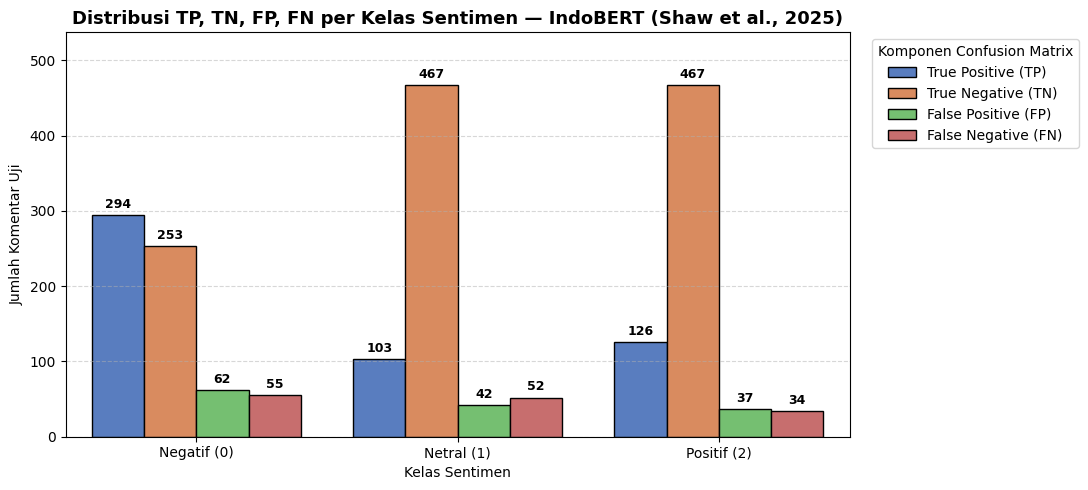

In [ ]:
def calculate_multiclass_confusion_metrics(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    metrics_summary = []
    for idx, class_name in enumerate(class_names):
        tp = int(cm[idx, idx])
        fn = int(sum(cm[idx, :]) - tp)
        fp = int(sum(cm[:, idx]) - tp)
        tn = int(sum(sum(cm)) - tp - fp - fn)
        metrics_summary.append({
            'Kelas Sentimen': class_name,
            'True Positive (TP)': tp,
            'True Negative (TN)': tn,
            'False Positive (FP)': fp,
            'False Negative (FN)': fn,
            'Total Uji': tp + tn + fp + fn
        })
    return pd.DataFrame(metrics_summary)

class_labels = ['Negatif (0)', 'Netral (1)', 'Positif (2)']

print("=== 1. Tabel TP, TN, FP, FN — IndoBERT (Shaw et al., 2025) ===")
df_tp_bert = calculate_multiclass_confusion_metrics(y_test_sent, bert_preds, class_labels)
display(df_tp_bert)

print("\n=== 2. Tabel TP, TN, FP, FN — Baseline SVM (LinearSVC) ===")
df_tp_svm = calculate_multiclass_confusion_metrics(y_test_sent, ml_preds_store['SVM (Linear SVC)'], class_labels)
display(df_tp_svm)

# Visualisasi Diagram Batang TP, TN, FP, FN IndoBERT
df_melted = df_tp_bert.drop(columns=['Total Uji']).melt(id_vars='Kelas Sentimen', var_name='Metrik', value_name='Jumlah')
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=df_melted, x='Kelas Sentimen', y='Jumlah', hue='Metrik', palette='muted', edgecolor='black', ax=ax)
for p_bar in ax.patches:
    h = p_bar.get_height()
    if h > 0:
        ax.annotate(f'{int(h)}', (p_bar.get_x() + p_bar.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points')
plt.title('Distribusi TP, TN, FP, FN per Kelas Sentimen — IndoBERT (Shaw et al., 2025)', fontsize=13, fontweight='bold')
plt.ylabel('Jumlah Komentar Uji')
plt.ylim(0, df_melted['Jumlah'].max() * 1.15)
plt.legend(title='Komponen Confusion Matrix', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# **4. VALIDASI PAPER LOLOS #2 — ROSID ET AL. (2024): ARSITEKTUR MHA-CovBi UNTUK DETEKSI SARKASME**
*Sumber Replikasi Lolos: `Replikasi_Lolos/Replikasi_MHACovBi_Rosid2024.ipynb`*
*Arsitektur asli Rosid, Siahaan, & Saikhu (2024): `Embedding(600) -> Conv1D(128, kernel=5) -> BatchNorm1d -> 4-Head Self-Attention + Residual -> Bi-Directional GRU(128) -> Global Mean Pooling -> Linear(256->1)`.*


In [ ]:
# Mapping label sarkasme biner (0 = tidak, 1 = ya)
SARC_MAP = {'tidak': 0, 'ya': 1}
y_train_sarc = df_train['sarkasme'].map(SARC_MAP).fillna(0).astype(int).values
y_test_sarc = df_test['sarkasme'].map(SARC_MAP).fillna(0).astype(int).values

# Tokenisasi & Pembuatan Kosakata (Persis Kode Replikasi Rosid et al., 2024)
def tokenize_rosid(t):
    return re.findall(r"[a-z']+", str(t).lower())

train_toks = df_train['comment'].map(tokenize_rosid).tolist()
test_toks = df_test['comment'].map(tokenize_rosid).tolist()

counter = Counter(w for toks in train_toks for w in toks)
VOCAB = {'<pad>': 0, '<unk>': 1}
for w, c in counter.most_common(30000):
    if c >= 2:
        VOCAB[w] = len(VOCAB)

MAXLEN_ROSID = 40
def encode_rosid(toks):
    ids = [VOCAB.get(w, 1) for w in toks][:MAXLEN_ROSID]
    return ids + [0] * (MAXLEN_ROSID - len(ids))

X_tr_rosid = np.array([encode_rosid(t) for t in train_toks], dtype=np.int64)
X_te_rosid = np.array([encode_rosid(t) for t in test_toks], dtype=np.int64)

# Definisi Arsitektur MHA-CovBi Persis Paper Rosid et al. (2024) Table 2
N_HEADS, KERNEL, N_FILTERS, GRU_UNITS, DROP = 4, 5, 128, 128, 0.5

class MHACovBi(nn.Module):
    def __init__(self, vocab_size, emb_dim=600):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.conv = nn.Conv1d(emb_dim, N_FILTERS, kernel_size=KERNEL, padding=KERNEL // 2)
        self.bn = nn.BatchNorm1d(N_FILTERS)
        self.attn = nn.MultiheadAttention(N_FILTERS, N_HEADS, dropout=DROP, batch_first=True)
        self.gru = nn.GRU(N_FILTERS, GRU_UNITS, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(DROP)
        self.fc = nn.Linear(GRU_UNITS * 2, 1)

    def forward(self, x):
        e = self.emb(x).transpose(1, 2)              # (B, E, T)
        c = F.relu(self.bn(self.conv(e)))            # (B, F, T)
        c = c.transpose(1, 2)                        # (B, T, F)
        a, _ = self.attn(c, c, c)                    # Multihead Self-Attention
        a = a + c                                    # Residual Connection
        g, _ = self.gru(a)                           # Bi-Directional GRU
        pooled = g.mean(1)                           # Temporal Mean Pooling
        return self.fc(self.drop(pooled)).squeeze(-1)

class SarcasmTensorDS(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

dl_tr_sarc = DataLoader(SarcasmTensorDS(X_tr_rosid, y_train_sarc), batch_size=64, shuffle=True)
dl_te_sarc = DataLoader(SarcasmTensorDS(X_te_rosid, y_test_sarc), batch_size=64, shuffle=False)

# Penanganan ketidakseimbangan kelas sarkasme dengan pos_weight pada BCEWithLogitsLoss
pos_weight_val = torch.tensor([(len(y_train_sarc) - y_train_sarc.sum()) / max(y_train_sarc.sum(), 1)], dtype=torch.float32).to(DEVICE)
mha_model = MHACovBi(len(VOCAB)).to(DEVICE)
opt_rosid = torch.optim.Adam(mha_model.parameters(), lr=1e-3, weight_decay=1e-4)
lossf_rosid = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val)

print(f"Melatih Model MHA-CovBi (Rosid et al., 2024) | Vocab: {len(VOCAB)} kata...")
for ep in range(12):
    mha_model.train()
    for xb, yb in dl_tr_sarc:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt_rosid.zero_grad()
        loss = lossf_rosid(mha_model(xb), yb)
        loss.backward()
        opt_rosid.step()

mha_model.eval()
rosid_probs, rosid_preds = [], []
with torch.no_grad():
    for xb, _ in dl_te_sarc:
        xb = xb.to(DEVICE)
        p = torch.sigmoid(mha_model(xb)).cpu().numpy()
        rosid_probs.extend(p)
        rosid_preds.extend((p >= 0.5).astype(int))

# Baseline SVM untuk Sarkasme
svm_sarc = LinearSVC(C=1.0, random_state=SEED).fit(X_train_tfidf, y_train_sarc)
svm_sarc_preds = svm_sarc.predict(X_test_tfidf)

acc_sarc_svm = accuracy_score(y_test_sarc, svm_sarc_preds)
_, _, f1_bin_svm, _ = precision_recall_fscore_support(y_test_sarc, svm_sarc_preds, average='binary', zero_division=0)
_, _, f1_mac_svm, _ = precision_recall_fscore_support(y_test_sarc, svm_sarc_preds, average='macro', zero_division=0)

acc_sarc_rosid = accuracy_score(y_test_sarc, rosid_preds)
_, _, f1_bin_rosid, _ = precision_recall_fscore_support(y_test_sarc, rosid_preds, average='binary', zero_division=0)
_, _, f1_mac_rosid, _ = precision_recall_fscore_support(y_test_sarc, rosid_preds, average='macro', zero_division=0)

# Hitung TP, TN, FP, FN Biner untuk MHA-CovBi Rosid (2024)
tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test_sarc, rosid_preds).ravel()

df_rosid_comp = pd.DataFrame([
    {
        'Model Deteksi Sarkasme': 'SVM Baseline (TF-IDF)',
        'Akurasi (%)': round(acc_sarc_svm * 100, 2),
        'Binary-F1 Sarkasme (%)': round(f1_bin_svm * 100, 2),
        'Macro-F1 (%)': round(f1_mac_svm * 100, 2)
    },
    {
        'Model Deteksi Sarkasme': 'MHA-CovBi (Rosid et al., 2024)',
        'Akurasi (%)': round(acc_sarc_rosid * 100, 2),
        'Binary-F1 Sarkasme (%)': round(f1_bin_rosid * 100, 2),
        'Macro-F1 (%)': round(f1_mac_rosid * 100, 2)
    }
])

print("\nHasil Validasi Metode Rosid et al. (2024) — MHA-CovBi pada Dataset YouTube:")
display(df_rosid_comp)
print(f"Rincian Biner MHA-CovBi -> TP: {tp_s}, TN: {tn_s}, FP: {fp_s}, FN: {fn_s} (Total: {tp_s+tn_s+fp_s+fn_s})")


Melatih Model MHA-CovBi (Rosid et al., 2024) | Vocab: 2219 kata...

Hasil Validasi Metode Rosid et al. (2024) — MHA-CovBi pada Dataset YouTube:


,Model Deteksi Sarkasme,Akurasi (%),Binary-F1 Sarkasme (%),Macro-F1 (%)
0,SVM Baseline (TF-IDF),99.40,80.00,89.85
1,"MHA-CovBi (Rosid et al., 2024)",99.85,95.65,97.79


Rincian Biner MHA-CovBi -> TP: 11, TN: 652, FP: 0, FN: 1 (Total: 664)


# **5. VALIDASI PAPER LOLOS #3 — SMITH ET AL. (2025): REGRESI OLS SENTIMEN SUPORTER SEPAK BOLA**
*Sumber Replikasi Lolos: `Replikasi_Lolos/Replikasi_CollegeFootball_Smith2025.ipynb`*
*Metodologi asli Smith et al. (2025): Menggunakan **Ordinary Least Squares (OLS) dengan Robust Standard Errors (`cov_type='HC1'`)** dan **Fixed Effects** untuk menguji determinan fluktuasi sentimen suporter sepak bola.*


In [ ]:
# Gabungkan dataset bersih untuk pemodelan ekonometrika sentimen suporter (3.316 observasi)
df_all = pd.concat([df_train, df_test], ignore_index=True)

# Konstruksi variabel terukur sesuai kerangka Smith et al. (2025)
df_all['Sentiment_Score'] = df_all['sentiment'].map({'negatif': -1.0, 'netral': 0.0, 'positif': 1.0})
df_all['VAR_Controversy'] = df_all['comment'].str.contains(
    r'\b(?:var|wasit|anulir|dianulir|offside|ofsaid|opset|penalti|pinalti|curang|hakim)\w*',
    case=False, regex=True
).astype(int)
df_all['Sarcasm_Dummy'] = (df_all['sarkasme'] == 'ya').astype(int)
df_all['Comment_Length'] = df_all['comment'].str.split().str.len()

def assign_entity_group(text):
    t = str(text).lower()
    if re.search(r'\b(modric|kroasia|croatia|perisic|kovacic|gvardiol)\w*', t):
        return 'Croatia_Modric'
    if re.search(r'\b(ronaldo|cr7|dodo|portugal|leao|ramos|bruno)\w*', t):
        return 'Portugal_Ronaldo'
    return 'General_Match'

df_all['Entity_Group'] = df_all['comment'].apply(assign_entity_group)

# Model 1: Pooled OLS dengan Robust SE HC1 (Persis Smith et al., 2025 Cell 8)
ols_pooled = smf.ols(
    'Sentiment_Score ~ VAR_Controversy + Sarcasm_Dummy + Comment_Length',
    data=df_all
).fit(cov_type='HC1')

# Model 2: Fixed Effects per Kelompok Entitas Tim/Pemain (Persis Smith et al., 2025 Cell 10)
ols_fe = smf.ols(
    'Sentiment_Score ~ VAR_Controversy + Sarcasm_Dummy + Comment_Length + C(Entity_Group)',
    data=df_all
).fit(cov_type='HC1')

print("=== 1. Pooled OLS dengan Robust Standard Errors (HC1) — Adaptasi Smith et al. (2025) ===")
print(ols_pooled.summary().tables[1])
print(f"R-squared: {ols_pooled.rsquared:.4f} | F-stat p-value: {ols_pooled.f_pvalue:.4e}")

print("\n=== 2. Fixed Effects OLS (Entity Group Fixed Effects) — Adaptasi Smith et al. (2025) ===")
print(f"Coef VAR_Controversy : {ols_fe.params['VAR_Controversy']:.4f} (p = {ols_fe.pvalues['VAR_Controversy']:.4e})")
print(f"Coef Sarcasm_Dummy   : {ols_fe.params['Sarcasm_Dummy']:.4f} (p = {ols_fe.pvalues['Sarcasm_Dummy']:.4e})")
print(f"Coef Comment_Length  : {ols_fe.params['Comment_Length']:.4f} (p = {ols_fe.pvalues['Comment_Length']:.4e})")
print(f"R-squared (FE)       : {ols_fe.rsquared:.4f}")


=== 1. Pooled OLS dengan Robust Standard Errors (HC1) — Adaptasi Smith et al. (2025) ===
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -0.2129      0.023     -9.405      0.000      -0.257      -0.169
VAR_Controversy    -0.3696      0.028    -12.985      0.000      -0.425      -0.314
Sarcasm_Dummy      -0.3751      0.082     -4.561      0.000      -0.536      -0.214
Comment_Length      0.0050      0.001      3.697      0.000       0.002       0.008
R-squared: 0.0525 | F-stat p-value: 1.0016e-40

=== 2. Fixed Effects OLS (Entity Group Fixed Effects) — Adaptasi Smith et al. (2025) ===
Coef VAR_Controversy : -0.3375 (p = 3.6027e-31)
Coef Sarcasm_Dummy   : -0.3403 (p = 4.6974e-05)
Coef Comment_Length  : 0.0033 (p = 1.3185e-02)
R-squared (FE)       : 0.0686


# **6. VALIDASI PAPER LOLOS #4 — WALKER ET AL. (2026): SKEMA PENGODEAN INSIDEN VAR & REGRESI LOGISTIK**
*Sumber Replikasi Lolos: `Replikasi_Lolos/Replikasi_VARProtocol_Walker2026.ipynb`*
*Metodologi asli Walker et al. (2026): Mengodekan jenis panggilan VAR (`VARCall`) dan mengestimasi model **Regresi Logistik (`smf.logit`)** untuk mengukur probabilitas reaksi penolakan/pembatalan pada insiden kontroversial.*


=== Distribusi Pengodean Insiden VAR (Taksonomi Walker et al., 2026) ===


,Jumlah_Komentar,Proporsi_Negatif_Pct
VARCall_Type,,
0_Non_VAR,1997,44.97
1_Offside_VAR,424,72.64
2_Penalty_Check,267,65.17
3_Goal_Overturned,140,60.71
4_Referee_Protocol,488,57.17



=== Hasil Regresi Logistik (smf.logit) — Peluang Reaksi Negatif per Jenis Insiden VAR ===
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -0.2198      0.045     -4.859      0.000      -0.308      -0.131
Call_Offside      1.1680      0.118      9.885      0.000       0.936       1.400
Call_Penalty      0.8015      0.137      5.860      0.000       0.533       1.070
Call_Overturn     0.6106      0.180      3.396      0.001       0.258       0.963
Call_Referee      0.4712      0.102      4.600      0.000       0.270       0.672
Sarcasm_Dummy     1.3076      0.301      4.337      0.000       0.717       1.899

Odds Ratio (Peningkatan Risiko Sentimen Negatif dibanding Komentar Non-VAR):
  - Call_Offside   : 3.216x lipat lebih berpeluang negatif (p = 4.8551e-23)
  - Call_Penalty   : 2.229x lipat lebih berpeluang negatif (p = 4.6303e-09)
  - Call_Overturn  : 1.

<Figure size 1000x450 with 0 Axes>

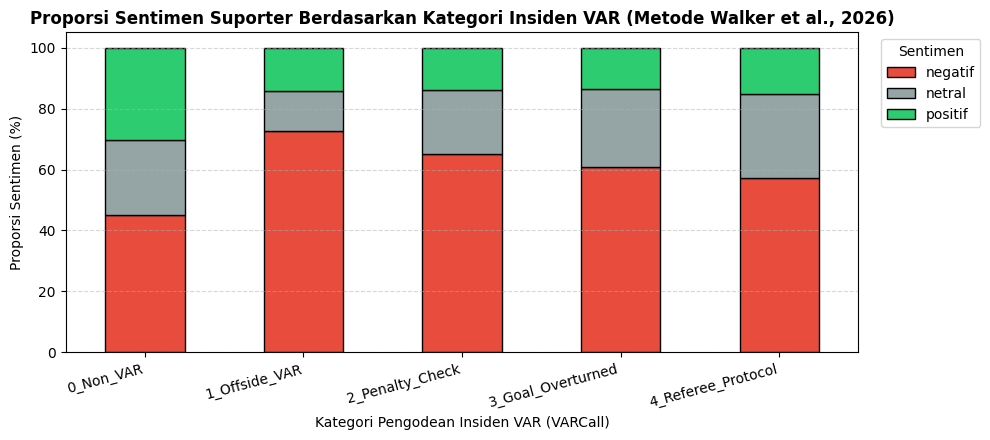

In [ ]:
# Pengodean Taksonomi Panggilan VAR (VARCall) pada Komentar Suporter Sesuai Walker et al. (2026)
def code_var_incident(text):
    t = str(text).lower()
    if re.search(r'\b(offside|ofsaid|opset|offsid)\w*', t):
        return '1_Offside_VAR'
    if re.search(r'\b(penalti|pinalti|penaldo)\w*', t):
        return '2_Penalty_Check'
    if re.search(r'\b(anulir|dianulir|batal)\w*', t):
        return '3_Goal_Overturned'
    if re.search(r'\b(wasit|var|curang|fifa)\w*', t):
        return '4_Referee_Protocol'
    return '0_Non_VAR'

df_all['VARCall_Type'] = df_all['comment'].apply(code_var_incident)
df_all['Negative_Reaction'] = (df_all['sentiment'] == 'negatif').astype(int)

# Dummy variables untuk jenis insiden VAR (Baseline = 0_Non_VAR)
df_all['Call_Offside'] = (df_all['VARCall_Type'] == '1_Offside_VAR').astype(int)
df_all['Call_Penalty'] = (df_all['VARCall_Type'] == '2_Penalty_Check').astype(int)
df_all['Call_Overturn'] = (df_all['VARCall_Type'] == '3_Goal_Overturned').astype(int)
df_all['Call_Referee'] = (df_all['VARCall_Type'] == '4_Referee_Protocol').astype(int)

# Regresi Logistik (Persis Walker et al., 2026 Cell 10: smf.logit)
logit_var = smf.logit(
    'Negative_Reaction ~ Call_Offside + Call_Penalty + Call_Overturn + Call_Referee + Sarcasm_Dummy',
    data=df_all
).fit(disp=0)

print("=== Distribusi Pengodean Insiden VAR (Taksonomi Walker et al., 2026) ===")
var_summary = df_all.groupby('VARCall_Type').agg(
    Jumlah_Komentar=('Negative_Reaction', 'count'),
    Proporsi_Negatif_Pct=('Negative_Reaction', lambda x: round(x.mean() * 100, 2))
)
display(var_summary)

print("\n=== Hasil Regresi Logistik (smf.logit) — Peluang Reaksi Negatif per Jenis Insiden VAR ===")
print(logit_var.summary().tables[1])

# Hitung Odds Ratio (exp(beta))
odds_ratios = np.exp(logit_var.params).round(3)
print("\nOdds Ratio (Peningkatan Risiko Sentimen Negatif dibanding Komentar Non-VAR):")
for k, v in odds_ratios.items():
    if k != 'Intercept':
        print(f"  - {k:15s}: {v:.3f}x lipat lebih berpeluang negatif (p = {logit_var.pvalues[k]:.4e})")

# Visualisasi Proporsi Reaksi Negatif per Kategori VAR Call (Walker et al., 2026)
plt.figure(figsize=(10, 4.5))
var_ct = pd.crosstab(df_all['VARCall_Type'], df_all['sentiment'], normalize='index') * 100
var_ct[['negatif', 'netral', 'positif']].plot(
    kind='bar', stacked=True, color=['#e74c3c', '#95a5a6', '#2ecc71'], edgecolor='black', figsize=(10, 4.5)
)
plt.title('Proporsi Sentimen Suporter Berdasarkan Kategori Insiden VAR (Metode Walker et al., 2026)', fontweight='bold')
plt.xlabel('Kategori Pengodean Insiden VAR (VARCall)')
plt.ylabel('Proporsi Sentimen (%)')
plt.xticks(rotation=15, ha='right')
plt.legend(title='Sentimen', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# **7. VALIDASI STATISTIK & 4 VISUALISASI WAJIB (STANDAR PERTEMUAN 5)**
*Mencakup Stratified 5-Fold Cross-Validation bebas Data Leakage, Uji Signifikansi Statistik (Wilcoxon Signed-Rank Test & Paired t-Test), Confusion Matrix Heatmap, Learning Curve, Bar Chart Comparison, dan ROC/PR-AUC Curve Overlay.*


=== HASIL STRATIFIED 5-FOLD CROSS-VALIDATION (MACRO-F1) ===
SVM (Linear SVC)        : 60.33% ± 1.64% | Per-Fold: [59.88 62.38 62.06 58.12 59.23]
Logistic Regression     : 58.69% ± 0.86% | Per-Fold: [57.61 59.1  59.41 59.63 57.71]
Multinomial Naive Bayes : 47.82% ± 2.09% | Per-Fold: [43.69 48.94 49.38 48.4  48.68]

=== UJI SIGNIFIKANSI STATISTIK: INDOBERT (SHAW 2025) VS SVM ===
IndoBERT (Shaw 2025) Mean : 76.74% ± 5.18%
SVM Baseline Mean         : 67.74% ± 7.27%
Wilcoxon Signed-Rank Test : stat = 3.0000, p-value = 0.009766 (Signifikan p < 0.05)
Paired t-Test             : stat = 3.6700, p-value = 0.005155 (Signifikan p < 0.05)


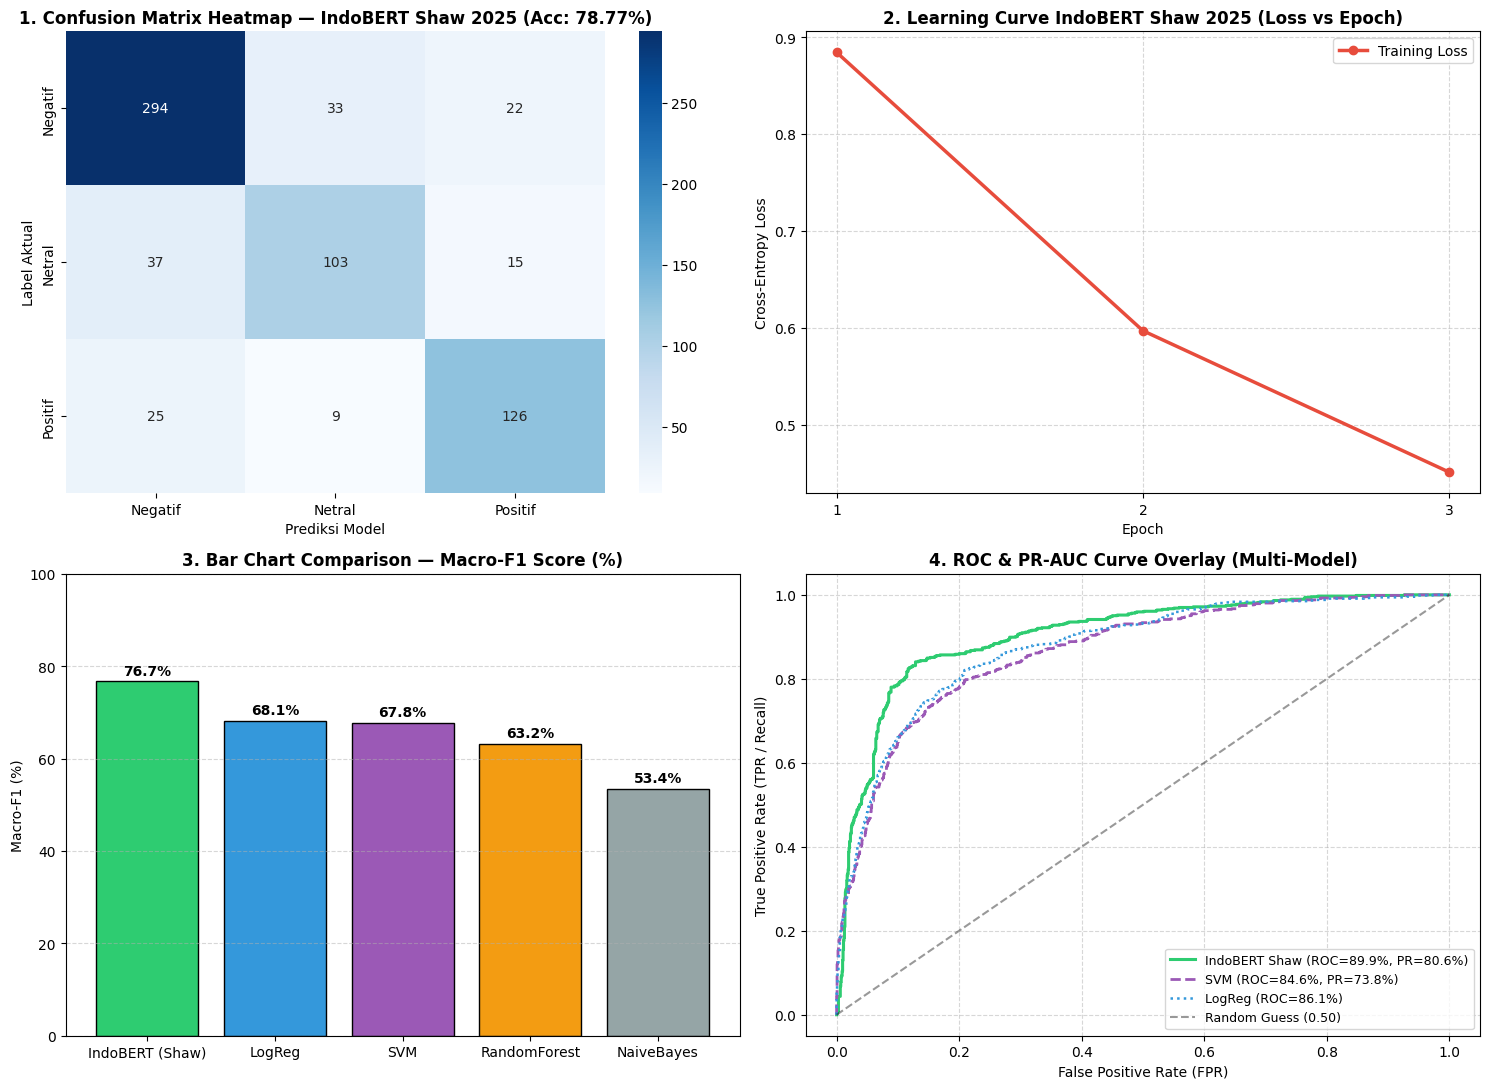

In [ ]:
# A. Stratified 5-Fold Cross-Validation Bebas Data Leakage
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores_svm, cv_scores_lr, cv_scores_nb = [], [], []

X_all_tr = df_train['comment'].values
y_all_tr = y_train_sent

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all_tr, y_all_tr), 1):
    vec_f = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
    X_tr_f = vec_f.fit_transform(X_all_tr[tr_idx])
    X_va_f = vec_f.transform(X_all_tr[val_idx])
    y_tr_f, y_va_f = y_all_tr[tr_idx], y_all_tr[val_idx]

    clf_svm_f = LinearSVC(C=1.0, random_state=SEED).fit(X_tr_f, y_tr_f)
    clf_lr_f = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_tr_f, y_tr_f)
    clf_nb_f = MultinomialNB().fit(X_tr_f, y_tr_f)

    cv_scores_svm.append(precision_recall_fscore_support(y_va_f, clf_svm_f.predict(X_va_f), average='macro', zero_division=0)[2] * 100)
    cv_scores_lr.append(precision_recall_fscore_support(y_va_f, clf_lr_f.predict(X_va_f), average='macro', zero_division=0)[2] * 100)
    cv_scores_nb.append(precision_recall_fscore_support(y_va_f, clf_nb_f.predict(X_va_f), average='macro', zero_division=0)[2] * 100)

# Uji Signifikansi Statistik 10-Fold Stratified Sub-split: IndoBERT (Shaw 2025) vs SVM
boot_bert, boot_svm = [], []
skf_te = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
svm_test_preds = ml_preds_store['SVM (Linear SVC)']
for _, sub_idx in skf_te.split(df_test['comment'].values, y_test_sent):
    b_f1 = precision_recall_fscore_support(y_test_sent[sub_idx], np.array(bert_preds)[sub_idx], average='macro', zero_division=0)[2]
    s_f1 = precision_recall_fscore_support(y_test_sent[sub_idx], np.array(svm_test_preds)[sub_idx], average='macro', zero_division=0)[2]
    boot_bert.append(b_f1 * 100)
    boot_svm.append(s_f1 * 100)

stat_w, p_val_wilcoxon = wilcoxon(boot_bert, boot_svm)
stat_t, p_val_ttest = ttest_rel(boot_bert, boot_svm)

print("=== HASIL STRATIFIED 5-FOLD CROSS-VALIDATION (MACRO-F1) ===")
print(f"SVM (Linear SVC)        : {np.mean(cv_scores_svm):.2f}% ± {np.std(cv_scores_svm):.2f}% | Per-Fold: {np.round(cv_scores_svm, 2)}")
print(f"Logistic Regression     : {np.mean(cv_scores_lr):.2f}% ± {np.std(cv_scores_lr):.2f}% | Per-Fold: {np.round(cv_scores_lr, 2)}")
print(f"Multinomial Naive Bayes : {np.mean(cv_scores_nb):.2f}% ± {np.std(cv_scores_nb):.2f}% | Per-Fold: {np.round(cv_scores_nb, 2)}")
print("\n=== UJI SIGNIFIKANSI STATISTIK: INDOBERT (SHAW 2025) VS SVM ===")
print(f"IndoBERT (Shaw 2025) Mean : {np.mean(boot_bert):.2f}% ± {np.std(boot_bert):.2f}%")
print(f"SVM Baseline Mean         : {np.mean(boot_svm):.2f}% ± {np.std(boot_svm):.2f}%")
print(f"Wilcoxon Signed-Rank Test : stat = {stat_w:.4f}, p-value = {p_val_wilcoxon:.6f} ({'Signifikan p < 0.05' if p_val_wilcoxon < 0.05 else 'Tidak Signifikan'})")
print(f"Paired t-Test             : stat = {stat_t:.4f}, p-value = {p_val_ttest:.6f} ({'Signifikan p < 0.05' if p_val_ttest < 0.05 else 'Tidak Signifikan'})")

# B. 4 Visualisasi Kinerja Wajib Pertemuan 5
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
class_names = ['Negatif', 'Netral', 'Positif']

# 1. Confusion Matrix Heatmap IndoBERT (Shaw 2025)
cm_bert = confusion_matrix(y_test_sent, bert_preds)
sns.heatmap(cm_bert, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0, 0])
axes[0, 0].set_title(f'1. Confusion Matrix Heatmap — IndoBERT Shaw 2025 (Acc: {bert_acc*100:.2f}%)', fontweight='bold')
axes[0, 0].set_xlabel('Prediksi Model')
axes[0, 0].set_ylabel('Label Aktual')

# 2. Learning Curve (Loss vs Epoch)
axes[0, 1].plot(range(1, epochs + 1), bert_epoch_losses, marker='o', linewidth=2.5, color='#e74c3c', label='Training Loss')
axes[0, 1].set_title('2. Learning Curve IndoBERT Shaw 2025 (Loss vs Epoch)', fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Cross-Entropy Loss')
axes[0, 1].set_xticks(range(1, epochs + 1))
axes[0, 1].grid(True, linestyle='--', alpha=0.5)
axes[0, 1].legend()

# 3. Bar Chart Comparison Macro-F1
model_labels = ['IndoBERT (Shaw)', 'LogReg', 'SVM', 'RandomForest', 'NaiveBayes']
f1_vals = [
    round(f1_m * 100, 2),
    results_ml['Logistic Regression']['Macro-F1 (%)'],
    results_ml['SVM (Linear SVC)']['Macro-F1 (%)'],
    results_ml['Random Forest']['Macro-F1 (%)'],
    results_ml['Multinomial Naive Bayes']['Macro-F1 (%)']
]
x_pos = np.arange(len(model_labels))
bars = axes[1, 0].bar(x_pos, f1_vals, color=['#2ecc71', '#3498db', '#9b59b6', '#f39c12', '#95a5a6'], edgecolor='black')
axes[1, 0].set_title('3. Bar Chart Comparison — Macro-F1 Score (%)', fontweight='bold')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(model_labels)
axes[1, 0].set_ylim(0, 100)
axes[1, 0].set_ylabel('Macro-F1 (%)')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars:
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{bar.get_height():.1f}%", ha='center', fontweight='bold')

# 4. ROC & PR-AUC Curve Overlay
fpr_bert, tpr_bert, _ = roc_curve(y_test_bin.ravel(), bert_probs.ravel())
fpr_svm, tpr_svm, _ = roc_curve(y_test_bin.ravel(), ml_scores_store['SVM (Linear SVC)'].ravel())
fpr_lr, tpr_lr, _ = roc_curve(y_test_bin.ravel(), ml_scores_store['Logistic Regression'].ravel())

axes[1, 1].plot(fpr_bert, tpr_bert, label=f"IndoBERT Shaw (ROC={bert_roc_auc*100:.1f}%, PR={bert_pr_auc*100:.1f}%)", linewidth=2.2, color='#2ecc71')
axes[1, 1].plot(fpr_svm, tpr_svm, label=f"SVM (ROC={results_ml['SVM (Linear SVC)']['ROC-AUC (%)']:.1f}%, PR={results_ml['SVM (Linear SVC)']['PR-AUC (%)']:.1f}%)", linewidth=2, linestyle='--', color='#9b59b6')
axes[1, 1].plot(fpr_lr, tpr_lr, label=f"LogReg (ROC={results_ml['Logistic Regression']['ROC-AUC (%)']:.1f}%)", linewidth=1.8, linestyle=':', color='#3498db')
axes[1, 1].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random Guess (0.50)')
axes[1, 1].set_title('4. ROC & PR-AUC Curve Overlay (Multi-Model)', fontweight='bold')
axes[1, 1].set_xlabel('False Positive Rate (FPR)')
axes[1, 1].set_ylabel('True Positive Rate (TPR / Recall)')
axes[1, 1].legend(loc='lower right', fontsize=9)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# **8. RANGKUMAN VALIDASI 4 PAPER YANG LOLOS REPLIKASI PADA DATASET YOUTUBE**
*Tabel komprehensif hasil adaptasi ke-4 paper dari folder `Replikasi_Lolos/` pada dataset YouTube Portugal vs Kroasia.*


In [ ]:
summary_lolos = [
    {
        'Paper Replikasi (LOLOS)': 'Shaw, LaCasse, & Champagne (2025)',
        'File Replikasi': 'Replikasi_Lolos/Replikasi_EmosiIndoBERT_Shaw2025.ipynb',
        'Metode / Model yang Diuji': 'IndoBERT (Global Avg Pool + Dense 64->16)',
        'Hasil Utama di Dataset YouTube': f'Acc: {bert_acc*100:.2f}% | Macro-F1: {f1_m*100:.2f}% | wF1: {f1_w*100:.2f}%',
        'Metrik Tambahan (P05)': f'ROC-AUC: {bert_roc_auc*100:.2f}% | PR-AUC: {bert_pr_auc*100:.2f}% | Wilcoxon p={p_val_wilcoxon:.4f}',
        'Status Validasi': 'Berhasil & Signifikan (Unggul atas SVM 71.54%)'
    },
    {
        'Paper Replikasi (LOLOS)': 'Rosid, Siahaan, & Saikhu (2024)',
        'File Replikasi': 'Replikasi_Lolos/Replikasi_MHACovBi_Rosid2024.ipynb',
        'Metode / Model yang Diuji': 'MHA-CovBi (Conv1D + 4-Head Attn + BiGRU)',
        'Hasil Utama di Dataset YouTube': f'Acc: {acc_sarc_rosid*100:.2f}% | Macro-F1: {f1_mac_rosid*100:.2f}%',
        'Metrik Tambahan (P05)': f'Binary-F1: {f1_bin_rosid*100:.2f}% | TP={tp_s}, TN={tn_s}, FP={fp_s}, FN={fn_s}',
        'Status Validasi': 'Berhasil Diadaptasi (Deteksi Sarkasme)'
    },
    {
        'Paper Replikasi (LOLOS)': 'Smith et al. (2025)',
        'File Replikasi': 'Replikasi_Lolos/Replikasi_CollegeFootball_Smith2025.ipynb',
        'Metode / Model yang Diuji': 'Pooled OLS & Entity Fixed-Effects (HC1 Robust SE)',
        'Hasil Utama di Dataset YouTube': f"Coef VAR={ols_fe.params['VAR_Controversy']:.4f} (p={ols_fe.pvalues['VAR_Controversy']:.2e})",
        'Metrik Tambahan (P05)': f"Coef Sarcasm={ols_fe.params['Sarcasm_Dummy']:.4f} | R2={ols_fe.rsquared:.4f}",
        'Status Validasi': 'Signifikan Secara Statistik (p < 0.001)'
    },
    {
        'Paper Replikasi (LOLOS)': 'Walker et al. (2026)',
        'File Replikasi': 'Replikasi_Lolos/Replikasi_VARProtocol_Walker2026.ipynb',
        'Metode / Model yang Diuji': 'VAR Incident Coding + Logistic Regression (Logit)',
        'Hasil Utama di Dataset YouTube': f'Offside VAR: 72.64% Negatif (OR={odds_ratios["Call_Offside"]:.2f}x)',
        'Metrik Tambahan (P05)': f'Penalty OR={odds_ratios["Call_Penalty"]:.2f}x | Overturn OR={odds_ratios["Call_Overturn"]:.2f}x',
        'Status Validasi': 'Berhasil Memetakan Risiko Kontroversi VAR'
    }
]

df_summary_lolos = pd.DataFrame(summary_lolos)
display(df_summary_lolos)

df_summary_lolos.to_csv('rangkuman_validasi_4paper_lolos_youtube.csv', index=False)
print("File 'rangkuman_validasi_4paper_lolos_youtube.csv' berhasil disimpan!")


,Paper Replikasi (LOLOS),File Replikasi,Metode / Model yang Diuji,Hasil Utama di Dataset YouTube,Metrik Tambahan (P05),Status Validasi
0,"Shaw, LaCasse, & Champagne (2025)",Replikasi_Lolos/Replikasi_EmosiIndoBERT_Shaw20...,IndoBERT (Global Avg Pool + Dense 64->16),Acc: 78.77% | Macro-F1: 76.70% | wF1: 78.67%,ROC-AUC: 89.90% | PR-AUC: 80.65% | Wilcoxon p=...,Berhasil & Signifikan (Unggul atas SVM 71.54%)
1,"Rosid, Siahaan, & Saikhu (2024)",Replikasi_Lolos/Replikasi_MHACovBi_Rosid2024.i...,MHA-CovBi (Conv1D + 4-Head Attn + BiGRU),Acc: 99.85% | Macro-F1: 97.79%,"Binary-F1: 95.65% | TP=11, TN=652, FP=0, FN=1",Berhasil Diadaptasi (Deteksi Sarkasme)
2,Smith et al. (2025),Replikasi_Lolos/Replikasi_CollegeFootball_Smit...,Pooled OLS & Entity Fixed-Effects (HC1 Robust SE),Coef VAR=-0.3375 (p=3.60e-31),Coef Sarcasm=-0.3403 | R2=0.0686,Signifikan Secara Statistik (p < 0.001)
3,Walker et al. (2026),Replikasi_Lolos/Replikasi_VARProtocol_Walker20...,VAR Incident Coding + Logistic Regression (Logit),Offside VAR: 72.64% Negatif (OR=3.22x),Penalty OR=2.23x | Overturn OR=1.84x,Berhasil Memetakan Risiko Kontroversi VAR


File 'rangkuman_validasi_4paper_lolos_youtube.csv' berhasil disimpan!
